# Worksheet 1: Warehouse Robots and Optimization
**6FTC2086: Social and Collective Artificial Intelligence**

This notebook implements all four assessed sections. Run cells from top to bottom.
Random seeds make the results reproducible. Dependencies: NumPy, pandas and Matplotlib.

**References supplied with the task:** `Resources/2026_Worksheet_1.pdf`,
`Resources/Practicals/SCAI_Practical_1_Pushing.ipynb`, and `Resources/Practicals/Practical_2.pdf`.
The grid/agent class structure follows the first practical's approach; the warehouse
uses simultaneous collision resolution instead of pushing, diagonal moves or leaving the grid.
The GA uses selection, crossover and mutation as in Practical 2, with this worksheet's objective.

In [1]:
from dataclasses import dataclass
from collections import defaultdict
from itertools import product
import random
import numpy
import pandas
import matplotlib.pyplot as pyplot
from IPython.display import display, Markdown

pyplot.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.25, 'figure.dpi': 110})
pandas.set_option('display.max_columns', 20)

## Part A, Task 1: Basic warehouse navigation

The world is a 6 × 6 grid. Four robots and eight packages are sampled without replacement,
so no two starting objects overlap. Each robot starts with 5 energy.

The worksheet leaves the movement policy and some update details unspecified. We use these conventions:

- Each robot chooses uniformly among orthogonally adjacent cells that are inside the grid
  and unoccupied by robots **at the start of the step**. Packages do not block movement.
  There is no global routing or preference for packages. If no cell is available, it waits for free.
- All proposals are collected before movement. Two or more proposals for the same cell cause
  one collision **event**. All participants stay put and each pays 1 attempted-move energy
  plus 1 additional collision energy. We also record the number of robot involvements.
- A successful move costs 1 energy. A package is collected once, gives +3 energy, and disappears.
  Movement and collection form one transition; removal occurs afterwards if energy is ≤ 0.
  Thus a robot with 1 energy can reach a package and finish the step with 3 energy.
- Robots cannot swap or enter a cell vacated during the same step. Packages do not respawn.
  All 40 steps are recorded, including empty steps after the final robot dies.

These explicit choices avoid ordering advantages and ensure robots never share a cell.

In [2]:
@dataclass
class Robot:
    """One robot with a grid position, remaining energy and collection count."""
    robot_name: str
    position: tuple
    energy: int = 5
    packages_collected: int = 0


class Warehouse:
    """Simultaneous grid simulation with finite packages and robot energy."""
    DIRECTIONS = ((-1, 0), (1, 0), (0, -1), (0, 1))

    def __init__(self, robot_count=4, package_count=8, grid_size=6, random_seed=42):
        if grid_size < 1 or robot_count < 0 or package_count < 0:
            raise ValueError('Size must be positive and object counts nonnegative.')
        if robot_count + package_count > grid_size * grid_size:
            raise ValueError('Not enough distinct grid cells.')
        self.grid_size = grid_size
        self.random_generator = random.Random(random_seed)
        initial_object_positions = self.random_generator.sample(list(product(range(grid_size), repeat=2)), robot_count + package_count)
        self.robots = {f'R{robot_index+1}': Robot(f'R{robot_index+1}', initial_object_positions[robot_index]) for robot_index in range(robot_count)}
        self.packages = set(initial_object_positions[robot_count:])
        self.initial_package_count = package_count
        self.packages_collected = self.collisions = self.collision_involvements = self.time_step = 0
        self.step_records = [self.record_metrics()]
        self.snapshots = [self.capture_snapshot()]

    def record_metrics(self):
        """Return the current totals for one simulation time step."""
        return {'step': self.time_step, 'survivors': len(self.robots), 'packages_collected': self.packages_collected, 'collisions': self.collisions, 'collision_involvements': self.collision_involvements, 'remaining_packages': len(self.packages), 'total_energy': sum(robot.energy for robot in self.robots.values())}

    def capture_snapshot(self):
        """Copy positions and energy so later moves cannot alter previous snapshots."""
        return {'step': self.time_step, 'packages': set(self.packages), 'robots': {robot_name: (robot.position, robot.energy) for robot_name, robot in self.robots.items()}}

    def available_neighbor_positions(self, robot, occupied_positions):
        """Return orthogonal, in-bounds neighbors without a robot at step start."""
        row, column = robot.position
        return [(row+row_offset, column+column_offset) for row_offset, column_offset in self.DIRECTIONS if 0 <= row+row_offset < self.grid_size and 0 <= column+column_offset < self.grid_size and (row+row_offset, column+column_offset) not in occupied_positions]

    def step(self, forced_targets=None):
        # Optional explicit proposals make edge-case checks deterministic.
        occupied_positions = {robot.position for robot in self.robots.values()}
        robots_by_target = defaultdict(list)
        for robot_name, robot in self.robots.items():
            available_targets = self.available_neighbor_positions(robot, occupied_positions)
            if forced_targets is None:
                target_position = self.random_generator.choice(available_targets) if available_targets else None
            else:
                target_position = forced_targets.get(robot_name)
                if target_position is not None and target_position not in available_targets:
                    raise ValueError('Target must be adjacent, in bounds and unoccupied.')
            if target_position is not None:
                robots_by_target[target_position].append(robot_name)

        # Resolve all proposals against the same start-of-step state.
        for target_position, robot_names in robots_by_target.items():
            if len(robot_names) > 1:
                self.collisions += 1
                self.collision_involvements += len(robot_names)
                for robot_name in robot_names:
                    self.robots[robot_name].energy -= 2
            else:
                robot = self.robots[robot_names[0]]
                robot.position = target_position
                robot.energy -= 1
                if target_position in self.packages:
                    self.packages.remove(target_position)
                    robot.energy += 3
                    robot.packages_collected += 1
                    self.packages_collected += 1

        self.robots = {robot_name: robot for robot_name, robot in self.robots.items() if robot.energy > 0}
        self.time_step += 1
        assert len({robot.position for robot in self.robots.values()}) == len(self.robots)
        assert self.packages_collected + len(self.packages) == self.initial_package_count
        self.step_records.append(self.record_metrics())
        self.snapshots.append(self.capture_snapshot())

    def run(self, step_count=40):
        for _ in range(step_count):
            self.step()
        return pandas.DataFrame(self.step_records)


warehouse = Warehouse(random_seed=42)
basic_simulation_history = warehouse.run(40)
display(basic_simulation_history.tail(1).set_index('step'))
display(pandas.DataFrame([{'robot': robot.robot_name, 'position': robot.position, 'energy': robot.energy, 'packages': robot.packages_collected} for robot in warehouse.robots.values()], columns=['robot', 'position', 'energy', 'packages']))
print(f'After 40 steps: {len(warehouse.robots)} survivors, {warehouse.packages_collected} packages ' f'collected, {warehouse.collisions} collision events ' f'({warehouse.collision_involvements} robot involvements).')

,survivors,packages_collected,collisions,collision_involvements,remaining_packages,total_energy
step,,,,,,
40,0,5,2,4,3,0


,robot,position,energy,packages


After 40 steps: 0 survivors, 5 packages collected, 2 collision events (4 robot involvements).


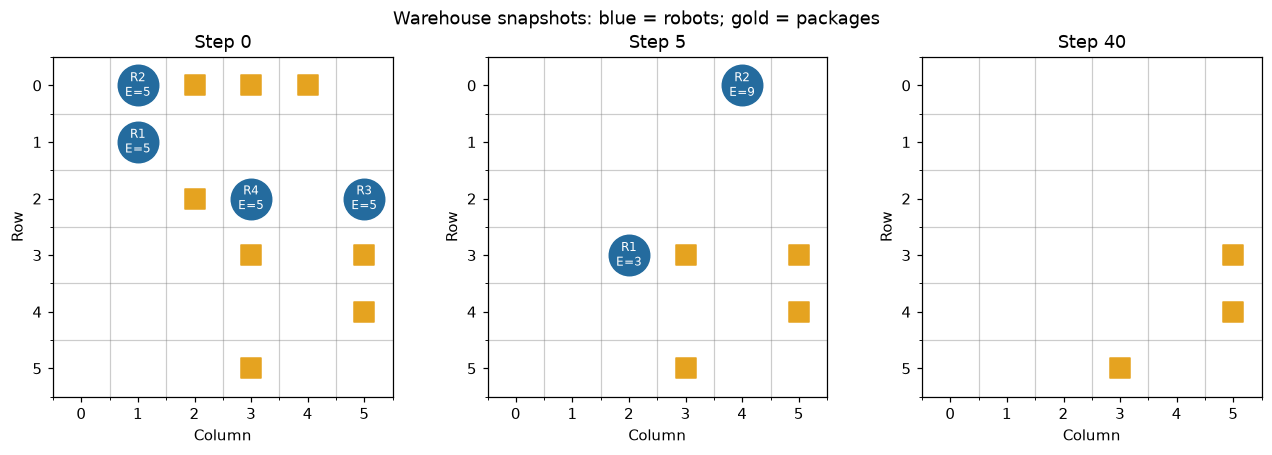

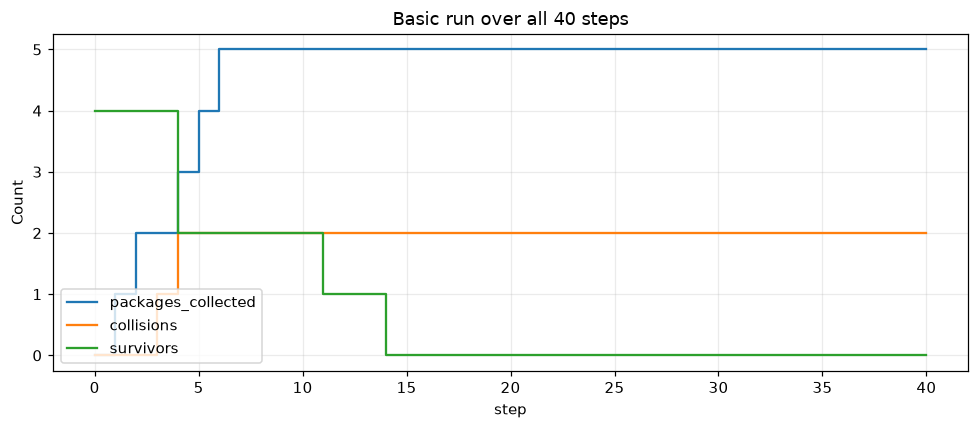

In [3]:
def plot_grid(warehouse_snapshot, plot_axis, grid_size=6):
    plot_axis.set(xlim=(-0.5, grid_size-0.5), ylim=(grid_size-0.5, -0.5), xticks=range(grid_size), yticks=range(grid_size), title=f"Step {warehouse_snapshot['step']}", xlabel='Column', ylabel='Row')
    plot_axis.set_aspect('equal')
    plot_axis.grid(False)
    plot_axis.set_xticks(numpy.arange(-0.5, grid_size, 1), minor=True)
    plot_axis.set_yticks(numpy.arange(-0.5, grid_size, 1), minor=True)
    plot_axis.grid(which='minor', color='gray', alpha=0.4)
    for row, column in sorted(warehouse_snapshot['packages']):
        plot_axis.scatter(column, row, marker='s', s=160, color='#e5a320')
    for robot_name, ((row, column), energy) in warehouse_snapshot['robots'].items():
        plot_axis.scatter(column, row, s=700, color='#246b9e')
        plot_axis.text(column, row, f'{robot_name}\nE={energy}', color='white', ha='center', va='center', fontsize=8)

figure, plot_axes = pyplot.subplots(1, 3, figsize=(12, 4))
for plot_axis, snapshot_step in zip(plot_axes, [0, 5, 40]):
    plot_grid(warehouse.snapshots[snapshot_step], plot_axis)
figure.suptitle('Warehouse snapshots: blue = robots; gold = packages')
pyplot.tight_layout()
pyplot.show()

basic_simulation_history.plot(x='step', y=['packages_collected', 'collisions', 'survivors'], drawstyle='steps-post', title='Basic run over all 40 steps')
pyplot.ylabel('Count')
pyplot.tight_layout()
pyplot.show()

### Rule checks
The checks below deliberately create collisions and energy boundary cases, rather than
relying on random runs to exercise the rules. A contested package must remain uncollected.

In [4]:
def create_test_warehouse(robots, packages=()):
    test_warehouse = Warehouse(0, 0)
    test_warehouse.robots = {robot.robot_name: robot for robot in robots}
    test_warehouse.packages = set(packages)
    test_warehouse.initial_package_count = len(packages)
    return test_warehouse

test_warehouse = create_test_warehouse([Robot('A', (1, 0)), Robot('B', (1, 2)), Robot('C', (0, 1))], [(1, 1)])
test_warehouse.step({'A': (1, 1), 'B': (1, 1), 'C': (1, 1)})
assert [robot.position for robot in test_warehouse.robots.values()] == [(1, 0), (1, 2), (0, 1)]
assert all(robot.energy == 3 for robot in test_warehouse.robots.values())
assert (test_warehouse.collisions, test_warehouse.collision_involvements, test_warehouse.packages_collected) == (1, 3, 0)
assert (1, 1) in test_warehouse.packages
test_warehouse = create_test_warehouse([Robot('A', (0, 0), 1)], [(0, 1)])
test_warehouse.step({'A': (0, 1)})
assert test_warehouse.robots['A'].energy == 3 and test_warehouse.packages_collected == 1 and not test_warehouse.packages
test_warehouse = create_test_warehouse([Robot('A', (0, 0), 1)])
test_warehouse.step({'A': (0, 1)})
assert not test_warehouse.robots
test_warehouse = create_test_warehouse([Robot('A', (1, 0), 2), Robot('B', (1, 2), 2)])
test_warehouse.step({'A': (1, 1), 'B': (1, 1)})
assert not test_warehouse.robots and test_warehouse.collisions == 1
test_warehouse = create_test_warehouse([Robot('A', (0, 0)), Robot('B', (0, 1))])
assert test_warehouse.available_neighbor_positions(test_warehouse.robots['A'], {(0, 0), (0, 1)}) == [(1, 0)]
assert len(basic_simulation_history) == 41 and basic_simulation_history.iloc[-1]['step'] == 40
print('Passed: simultaneous collision, penalty, collection, energy removal, boundaries and occupancy.')

Passed: simultaneous collision, penalty, collection, energy removal, boundaries and occupancy.


## Part A, Task 2: Experimental analysis

We compare 2 and 4 robots with **4 packages (low density, 11.1% of cells)** and
**12 packages (high density, 33.3%)**. These densities are experimental choices; the
basic run above still uses the required 8 packages. Each of the four conditions has
100 independently seeded runs of 40 steps. Initial robot density is 5.6% or 11.1%.

We measure total collection, collision events and survivors, plus packages per initial
robot and the fraction of available packages collected. The latter measures distinguish
total throughput from efficiency. Plot error bars show one standard deviation across runs,
not confidence intervals. The policy is identical in all conditions.

collected        collisions        survivors      per_robot  \
                     mean    std       mean    std      mean  std      mean   
robots packages                                                               
2      4             0.97  0.893       0.16  0.395       0.0  0.0     0.485   
       12            3.60  2.113       0.10  0.362       0.0  0.0     1.800   
4      4             1.93  1.139       0.69  0.849       0.0  0.0     0.482   
       12            6.55  2.694       0.80  0.865       0.0  0.0     1.638   

                       collection_fraction         
                   std                mean    std  
robots packages                                    
2      4         0.446               0.242  0.223  
       12        1.056               0.300  0.176  
4      4         0.285               0.482  0.285  
       12        0.674               0.546  0.225

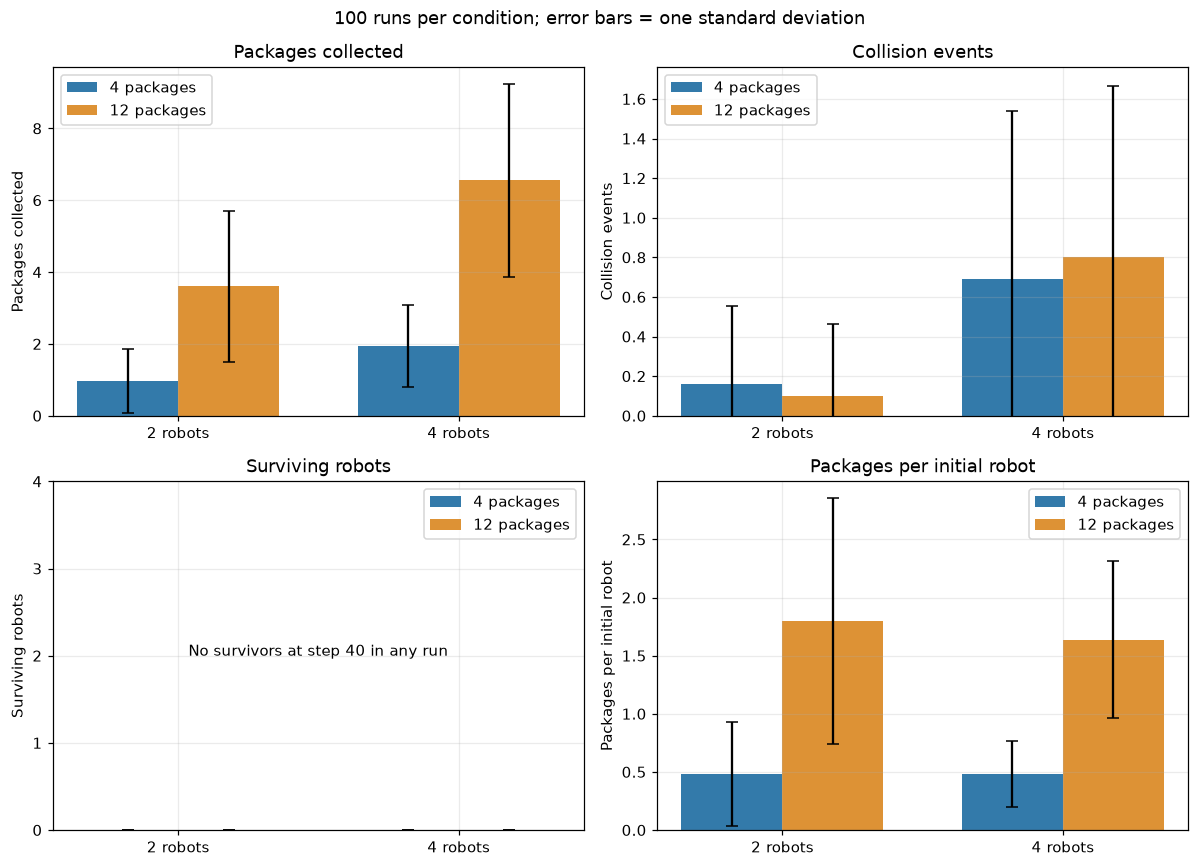

### Observed results

With **4 packages**, raising the robot count from 2 to 4 changed mean collection from **0.97** to **1.93**, collisions from **0.16** to **0.69**, and packages per robot from **0.485** to **0.482** (decreased).

With **12 packages**, raising the robot count from 2 to 4 changed mean collection from **3.60** to **6.55**, collisions from **0.10** to **0.80**, and packages per robot from **1.800** to **1.637** (decreased).

In [5]:
experiment_records = []
for robot_count in (2, 4):
    for package_count in (4, 12):
        for repetition_index in range(100):
            random_seed = 10000*robot_count + 100*package_count + repetition_index
            experiment_warehouse = Warehouse(robot_count, package_count, random_seed=random_seed)
            experiment_warehouse.run(40)
            experiment_records.append({'robots': robot_count, 'packages': package_count, 'seed': random_seed, 'collected': experiment_warehouse.packages_collected, 'collisions': experiment_warehouse.collisions, 'survivors': len(experiment_warehouse.robots), 'per_robot': experiment_warehouse.packages_collected / robot_count, 'collection_fraction': experiment_warehouse.packages_collected / package_count})
experiment_results = pandas.DataFrame(experiment_records)
performance_metrics = ['collected', 'collisions', 'survivors', 'per_robot', 'collection_fraction']
experiment_summary = experiment_results.groupby(['robots', 'packages'])[performance_metrics].agg(['mean', 'std'])
display(experiment_summary.round(3))

figure, plot_axes = pyplot.subplots(2, 2, figsize=(11, 8))
for plot_axis, metric_name, axis_label in zip(plot_axes.flat, ['collected', 'collisions', 'survivors', 'per_robot'], ['Packages collected', 'Collision events', 'Surviving robots', 'Packages per initial robot']):
    for bar_offset, package_count, bar_color in [(-0.18, 4, '#337aaa'), (0.18, 12, '#dd9235')]:
        condition_statistics = experiment_summary.xs(package_count, level='packages')[metric_name].reindex([2, 4])
        plot_axis.bar(numpy.arange(2)+bar_offset, condition_statistics['mean'], yerr=condition_statistics['std'], width=0.36, capsize=4, label=f'{package_count} packages', color=bar_color)
    plot_axis.set(xticks=[0, 1], xticklabels=['2 robots', '4 robots'], ylabel=axis_label, title=axis_label, ylim=(0, None))
    if metric_name == 'survivors':
        plot_axis.set_ylim(0, 4)
        plot_axis.set_yticks(range(5))
        if experiment_results['survivors'].max() == 0:
            plot_axis.text(0.5, 0.5, 'No survivors at step 40 in any run', transform=plot_axis.transAxes, ha='center')
    plot_axis.legend()
figure.suptitle('100 runs per condition; error bars = one standard deviation')
pyplot.tight_layout()
pyplot.show()

observation_paragraphs = []
for package_count in (4, 12):
    two_robot_statistics = experiment_summary.loc[(2, package_count)]
    four_robot_statistics = experiment_summary.loc[(4, package_count)]
    efficiency_change = 'increased' if four_robot_statistics[('per_robot', 'mean')] > two_robot_statistics[('per_robot', 'mean')] else 'decreased'
    observation_paragraphs.append(f"With **{package_count} packages**, raising the robot count from 2 to 4 " f"changed mean collection from **{two_robot_statistics[('collected', 'mean')]:.2f}** to " f"**{four_robot_statistics[('collected', 'mean')]:.2f}**, collisions from " f"**{two_robot_statistics[('collisions', 'mean')]:.2f}** to **{four_robot_statistics[('collisions', 'mean')]:.2f}**, " f"and packages per robot from **{two_robot_statistics[('per_robot', 'mean')]:.3f}** to " f"**{four_robot_statistics[('per_robot', 'mean')]:.3f}** ({efficiency_change}).")
display(Markdown('### Observed results\n\n' + '\n\n'.join(observation_paragraphs)))

### Interpretation and conclusions

In these runs, four robots collect more packages in total but experience more collisions
at both package densities. Per-robot collection is nearly unchanged at low package density
and falls at high density. Thus increased robot density gives higher total throughput,
alongside greater interference, without an observed gain in per-robot efficiency.
All robots are gone by step 40 in all four conditions, so final survival does not
distinguish the conditions in this experiment.

More robots explore more cells in parallel, but share a finite supply of packages and
can compete for the same target. Total collection and per-robot efficiency therefore
need not improve together. Increased collisions indicate spatial interference; a fall
in packages per robot also reflects resource sharing, so it cannot be attributed solely
to collisions. The numerical comparisons above distinguish these effects.

Higher package density offers more opportunities to replenish energy (+3 per collection),
which supports longer exploration and usually greater collection. Longer activity can
also create more opportunities for collisions, so a raw collision count is affected by
both crowding and time spent active.

Final survival is a coarse measure here: there is no recharge station or package respawn.
With four initial robots and eight packages, at most 20 + 24 = 44 energy units are available
across the whole run. Death by step 40 is consequently unsurprising under random movement.
The time-series plot provides context that an endpoint alone misses.

The main factors are robot density, package availability, initial placement, random movement,
and collision energy losses. These findings describe this local random policy and the stated
collision conventions, rather than proving a universal effect of adding robots. Repeated
runs reduce dependence on one placement; alternative policies or charging would be separate experiments.

## Part B: Task allocation objective

There are three robots A, B and C, and six indivisible jobs with workloads
`[4, 7, 3, 8, 5, 6]`. A chromosome/assignment is a list of six integers:
0 = A, 1 = B, 2 = C. Every gene assigns exactly one job to exactly one robot.

For robot loads $T_A,T_B,T_C$, minimize $F=\max(T_A,T_B,T_C)$, or equivalently
maximize fitness $-F$. Total workload is 33, so the average-load lower bound is 11.
An exhaustive check of the tiny $3^6=729$ search space gives an independent benchmark;
it is **not** used to initialize or guide either optimizer.

In [6]:
JOB_WORKLOADS = numpy.array([4, 7, 3, 8, 5, 6])
ALLOCATION_ROBOT_COUNT = 3
JOB_COUNT = len(JOB_WORKLOADS)

def calculate_robot_workloads(assignment):
    """Sum delivery-job workloads for robots A, B and C, in that order."""
    assignment_array = numpy.asarray(assignment)
    if assignment_array.shape != (JOB_COUNT,) or not numpy.all(numpy.isin(assignment_array, [0, 1, 2])):
        raise ValueError('An assignment needs six integer labels in 0..2.')
    return numpy.bincount(assignment_array.astype(int), weights=JOB_WORKLOADS, minlength=ALLOCATION_ROBOT_COUNT).astype(int)

def calculate_makespan(assignment):
    """Return the largest robot workload; a smaller makespan is better."""
    return int(calculate_robot_workloads(assignment).max())

def calculate_fitness(assignment):
    """Negate makespan so selection can maximize fitness."""
    return -calculate_makespan(assignment)

optimal_assignment = min(product(range(ALLOCATION_ROBOT_COUNT), repeat=JOB_COUNT), key=calculate_makespan)
OPTIMAL_MAKESPAN = calculate_makespan(optimal_assignment)
assert OPTIMAL_MAKESPAN == 11 and calculate_robot_workloads(optimal_assignment).sum() == 33
print('Exact benchmark:', list(optimal_assignment), 'loads:', calculate_robot_workloads(optimal_assignment), 'makespan:', OPTIMAL_MAKESPAN)

Exact benchmark: [0, 0, 1, 1, 2, 2] loads: [11 11 11] makespan: 11


## Part B, Part 1: Genetic algorithm

Start with 12 uniformly random chromosomes. Tournament selection samples three candidates
and chooses the one with greatest fitness. One-point crossover exchanges suffixes of two
parents. With probability 0.2 per child, mutation reassigns exactly one randomly selected
job to a different robot. One elite preserves the best chromosome; the remaining slots
are filled by offspring. Run 30 generations and record the best-so-far makespan,
including generation 0 before evolution.

In [7]:
def select_tournament_parent(population, random_generator, tournament_size=3):
    tournament_candidates = random_generator.sample(population, tournament_size)
    return max(tournament_candidates, key=calculate_fitness).copy()

def perform_one_point_crossover(first_parent, second_parent, random_generator):
    crossover_index = random_generator.randrange(1, JOB_COUNT)
    return (first_parent[:crossover_index] + second_parent[crossover_index:], second_parent[:crossover_index] + first_parent[crossover_index:])

def mutate_assignment(offspring_assignment, random_generator, mutation_probability=0.2):
    offspring_assignment = offspring_assignment.copy()
    if random_generator.random() < mutation_probability:
        job_index = random_generator.randrange(JOB_COUNT)
        offspring_assignment[job_index] = random_generator.choice([robot_index for robot_index in range(ALLOCATION_ROBOT_COUNT) if robot_index != offspring_assignment[job_index]])
    return offspring_assignment

def run_genetic_algorithm(random_seed=42, population_size=12, generation_count=30):
    random_generator = random.Random(random_seed)
    population = [[random_generator.randrange(ALLOCATION_ROBOT_COUNT) for _ in range(JOB_COUNT)] for _ in range(population_size)]
    best_assignment = max(population, key=calculate_fitness).copy()
    best_makespan_history = [calculate_makespan(best_assignment)]
    for _ in range(generation_count):
        next_population = [best_assignment.copy()]  # Elitism protects the incumbent.
        while len(next_population) < population_size:
            offspring_pair = perform_one_point_crossover(select_tournament_parent(population, random_generator), select_tournament_parent(population, random_generator), random_generator)
            for offspring_assignment in offspring_pair:
                if len(next_population) < population_size:
                    next_population.append(mutate_assignment(offspring_assignment, random_generator))
        population = next_population
        generation_best_assignment = max(population, key=calculate_fitness)
        if calculate_fitness(generation_best_assignment) > calculate_fitness(best_assignment):
            best_assignment = generation_best_assignment.copy()
        best_makespan_history.append(calculate_makespan(best_assignment))
    return {'best_assignment': best_assignment, 'makespan': calculate_makespan(best_assignment), 'best_makespan_history': best_makespan_history, 'population': population}

genetic_algorithm_result = run_genetic_algorithm()
print('GA assignment:', genetic_algorithm_result['best_assignment'], 'loads:', calculate_robot_workloads(genetic_algorithm_result['best_assignment']), 'makespan:', genetic_algorithm_result['makespan'], 'fitness:', calculate_fitness(genetic_algorithm_result['best_assignment']))

GA assignment: [1, 0, 1, 2, 1, 0] loads: [13 12  8] makespan: 13 fitness: -13


## Part B, Part 2: Particle swarm optimization

Use 12 particles and 30 iterations. Each particle stores a current integer assignment
and a real velocity for each of the six jobs, plus its personal best assignment.
The swarm also stores a global best. At each iteration:

$$v_i \leftarrow 0.7v_i + 1.5r_1(p_i-x_i) + 1.5r_2(g-x_i),$$
$$x_i \leftarrow \operatorname{clip}(\operatorname{round}(x_i+v_i),0,2).$$

Independent uniform random coefficients are drawn for each particle and job. Velocities
are clipped to [-2, 2] to limit overshoot. All particles use the same previous global best
in each update; personal and global bests are then updated using fitness = -makespan.
Copies prevent the stored best assignments changing accidentally when current positions change.

Rounding and clipping make standard PSO usable for this discrete task, but robot labels
are categorical: the numerical distance between A and C has no physical meaning.
This is a limitation of the encoding and can cause stagnation.

PSO assignment: [2, 2, 0, 0, 1, 1] loads: [11 11 11] makespan: 11 fitness: -11


,job,workload,GA robot,PSO robot
0,1,4,B,C
1,2,7,A,C
2,3,3,B,A
3,4,8,C,A
4,5,5,B,B
5,6,6,A,B


,method,A load,B load,C load,makespan,gap to optimum
0,GA,13,12,8,13,2
1,PSO,11,11,11,11,0


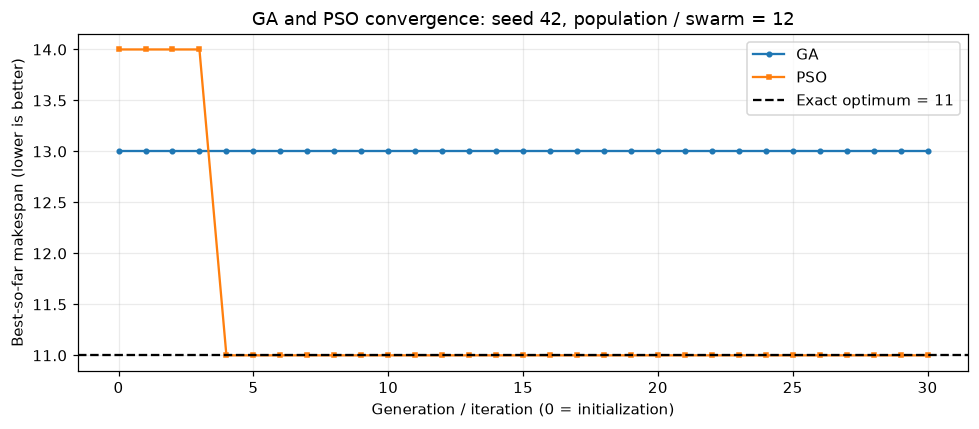

In [8]:
def run_particle_swarm_optimization(random_seed=42, particle_count=12, iteration_count=30, inertia_weight=0.7, cognitive_weight=1.5, social_weight=1.5):
    random_generator = numpy.random.default_rng(random_seed)
    particle_assignments = random_generator.integers(0, ALLOCATION_ROBOT_COUNT, size=(particle_count, JOB_COUNT))
    particle_velocities = random_generator.uniform(-1, 1, size=particle_assignments.shape)
    personal_best_assignments = particle_assignments.copy()
    personal_best_fitness = numpy.array([calculate_fitness(assignment_vector) for assignment_vector in personal_best_assignments])
    best_particle_index = int(numpy.argmax(personal_best_fitness))
    global_best_assignment = personal_best_assignments[best_particle_index].copy()
    global_best_fitness = int(personal_best_fitness[best_particle_index])
    best_makespan_history = [-global_best_fitness]
    for _ in range(iteration_count):
        cognitive_random_factors = random_generator.random(particle_assignments.shape)
        social_random_factors = random_generator.random(particle_assignments.shape)
        particle_velocities = (inertia_weight*particle_velocities + cognitive_weight*cognitive_random_factors*(personal_best_assignments-particle_assignments) + social_weight*social_random_factors*(global_best_assignment-particle_assignments))
        particle_velocities = numpy.clip(particle_velocities, -2, 2)
        particle_assignments = numpy.clip(numpy.rint(particle_assignments+particle_velocities), 0, ALLOCATION_ROBOT_COUNT-1).astype(int)
        current_particle_fitness = numpy.array([calculate_fitness(assignment_vector) for assignment_vector in particle_assignments])
        improved_particle_mask = current_particle_fitness > personal_best_fitness
        personal_best_assignments[improved_particle_mask] = particle_assignments[improved_particle_mask].copy()
        personal_best_fitness[improved_particle_mask] = current_particle_fitness[improved_particle_mask]
        best_particle_index = int(numpy.argmax(personal_best_fitness))
        if personal_best_fitness[best_particle_index] > global_best_fitness:
            global_best_assignment = personal_best_assignments[best_particle_index].copy()
            global_best_fitness = int(personal_best_fitness[best_particle_index])
        best_makespan_history.append(-global_best_fitness)
    return {'best_assignment': global_best_assignment.tolist(), 'makespan': -global_best_fitness, 'best_makespan_history': best_makespan_history, 'particle_assignments': particle_assignments, 'particle_velocities': particle_velocities, 'personal_best_assignments': personal_best_assignments, 'global_best_assignment': global_best_assignment}

particle_swarm_result = run_particle_swarm_optimization()
print('PSO assignment:', particle_swarm_result['best_assignment'], 'loads:', calculate_robot_workloads(particle_swarm_result['best_assignment']), 'makespan:', particle_swarm_result['makespan'], 'fitness:', calculate_fitness(particle_swarm_result['best_assignment']))

def create_allocation_table(optimization_result):
    return pandas.DataFrame({'job': numpy.arange(1, JOB_COUNT+1), 'workload': JOB_WORKLOADS, 'robot': ["ABC"[robot_index] for robot_index in optimization_result['best_assignment']]})

display(create_allocation_table(genetic_algorithm_result).rename(columns={'robot': 'GA robot'}).assign( **{'PSO robot': ['ABC'[robot_index] for robot_index in particle_swarm_result['best_assignment']]}))
display(pandas.DataFrame([{'method': algorithm_name, 'A load': calculate_robot_workloads(optimization_result['best_assignment'])[0], 'B load': calculate_robot_workloads(optimization_result['best_assignment'])[1], 'C load': calculate_robot_workloads(optimization_result['best_assignment'])[2], 'makespan': optimization_result['makespan'], 'gap to optimum': optimization_result['makespan']-OPTIMAL_MAKESPAN} for algorithm_name, optimization_result in [('GA', genetic_algorithm_result), ('PSO', particle_swarm_result)]]))

pyplot.plot(range(31), genetic_algorithm_result['best_makespan_history'], label='GA', marker='o', markersize=3)
pyplot.plot(range(31), particle_swarm_result['best_makespan_history'], label='PSO', marker='s', markersize=3)
pyplot.axhline(OPTIMAL_MAKESPAN, color='black', linestyle='--', label='Exact optimum = 11')
pyplot.xlabel('Generation / iteration (0 = initialization)')
pyplot.ylabel('Best-so-far makespan (lower is better)')
pyplot.title('GA and PSO convergence: seed 42, population / swarm = 12')
pyplot.legend()
pyplot.tight_layout()
pyplot.show()

### Repeated comparison and validation

One successful run does not establish that a stochastic optimizer is consistently better.
We therefore repeat each method with seeds 0–49 at the same population size and iteration
budget. The initial populations differ because the methods use different random generators;
this is a repeated outcome comparison, not a matched-population or runtime benchmark.
Success means achieving the independently verified optimum of 11.

In [9]:
optimizer_records = []
for random_seed in range(50):
    for algorithm_name, optimization_algorithm in [('GA', run_genetic_algorithm), ('PSO', run_particle_swarm_optimization)]:
        optimization_result = optimization_algorithm(random_seed=random_seed)
        assert len(optimization_result['best_makespan_history']) == 31
        assert all(previous_makespan >= next_makespan for previous_makespan, next_makespan in zip(optimization_result['best_makespan_history'], optimization_result['best_makespan_history'][1:]))
        assert calculate_makespan(optimization_result['best_assignment']) == optimization_result['makespan'] >= OPTIMAL_MAKESPAN
        assert sum(calculate_robot_workloads(optimization_result['best_assignment'])) == sum(JOB_WORKLOADS)
        if algorithm_name == 'GA':
            assert len(optimization_result['population']) == 12
            assert all(len(assignment_vector) == 6 and set(assignment_vector) <= {0, 1, 2} for assignment_vector in optimization_result['population'])
        else:
            assert optimization_result['particle_assignments'].shape == optimization_result['particle_velocities'].shape == (12, 6)
            assert numpy.isin(optimization_result['particle_assignments'], [0, 1, 2]).all()
        optimizer_records.append({'method': algorithm_name, 'seed': random_seed, 'makespan': optimization_result['makespan'], 'optimal': optimization_result['makespan'] == OPTIMAL_MAKESPAN})
optimizer_runs = pandas.DataFrame(optimizer_records)
optimizer_comparison = optimizer_runs.groupby('method').agg( best_makespan=('makespan', 'min'), mean_makespan=('makespan', 'mean'), std_makespan=('makespan', 'std'), worst_makespan=('makespan', 'max'), optimal_run_fraction=('optimal', 'mean'))
display(optimizer_comparison.round(3))

genetic_algorithm_success_rate = optimizer_comparison.loc['GA', 'optimal_run_fraction']
particle_swarm_success_rate = optimizer_comparison.loc['PSO', 'optimal_run_fraction']
if genetic_algorithm_success_rate > particle_swarm_success_rate:
    comparison_conclusion = 'GA was more reliable at finding the optimum in these runs.'
elif particle_swarm_success_rate > genetic_algorithm_success_rate:
    comparison_conclusion = 'PSO was more reliable at finding the optimum in these runs.'
else:
    comparison_conclusion = 'Both methods had the same optimum-hit rate in these runs.'
display(Markdown(f'''### Results and conclusion\n\nFor seed 42, GA obtained makespan **{genetic_algorithm_result['makespan']}** and PSO obtained\n**{particle_swarm_result['makespan']}**. Across 50 seeds, their optimum-hit rates were\n**{genetic_algorithm_success_rate:.0%}** and **{particle_swarm_success_rate:.0%}**, respectively. {comparison_conclusion}\n\nGA's categorical genes and reassignment mutation fit the discrete assignment problem\nnaturally. PSO shares useful assignments through personal and global bests, but rounding\ncan stop small changes from affecting assignments and may reduce diversity. Neither\nheuristic guarantees an optimum in 30 updates; their performance depends on seeds and\nparameters. The curves show best-so-far quality, so a flat segment means no improvement\nof the incumbent, not necessarily that every candidate stopped changing.\n\nFor only 729 assignments, exhaustive enumeration is a practical way to guarantee the\noptimum. The heuristic comparison is useful for understanding search behavior; it does\nnot establish superiority on larger scheduling problems.'''))
print('All simulation and optimizer checks passed.')

,best_makespan,mean_makespan,std_makespan,worst_makespan,optimal_run_fraction
method,,,,,
GA,11,12.02,0.742,13,0.26
PSO,11,11.80,0.728,13,0.38


### Results and conclusion

For seed 42, GA obtained makespan **13** and PSO obtained
**11**. Across 50 seeds, their optimum-hit rates were
**26%** and **38%**, respectively. PSO was more reliable at finding the optimum in these runs.

GA's categorical genes and reassignment mutation fit the discrete assignment problem
naturally. PSO shares useful assignments through personal and global bests, but rounding
can stop small changes from affecting assignments and may reduce diversity. Neither
heuristic guarantees an optimum in 30 updates; their performance depends on seeds and
parameters. The curves show best-so-far quality, so a flat segment means no improvement
of the incumbent, not necessarily that every candidate stopped changing.

For only 729 assignments, exhaustive enumeration is a practical way to guarantee the
optimum. The heuristic comparison is useful for understanding search behavior; it does
not establish superiority on larger scheduling problems.

All simulation and optimizer checks passed.
